### APM348 Midterm 1 Group

For the midterm, you can use one of these two versions of Euler's method:
- Euler's Method for 1st order ODEs
- Euler's Method for 2nd order ODEs


#### Euler's Method for 1st order ODEs

Below you can find code to run Euler's Method to approximate the solution of
$$ \frac{dy}{dt} = f(t,y) $$
with the **initial condition** $y(t_0) = y_0$.

The method will approximate the solution for the points $t_i = t_0 + i h$ for $i = 0, \ldots, n$ where the following information needs to be defined:
- `t_span`$ = ( t_0, t_n)$
- `h` where $n = \frac{t_n - t_0}{h}$ 
- `y0` = $y_0$
- `f(t,y)`

After running Euler's Method, the approximation will be stored as:
- `t` a list containing all the points $t_i$
- `y` a list containing the approximation of $y(t_i)$

The code will also plot the solution found.


#### Test questions

To answer the questions in the test, you may need to manipulate the variables to obtain the required information. 


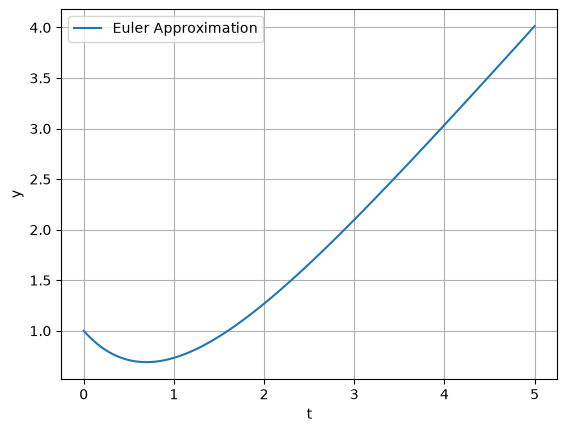

In [146]:
import numpy as np
import matplotlib.pyplot as plt

def euler_method(f, t_span, y0, h):
    """
    Approximates the solution of a first-order ODE using Euler's method.

    Args:
        f: The function defining the ODE, y' = f(t, y).
        t_span: A tuple (t0, tf) representing the start and end times.
        y0: The initial condition, y(t0).
        h: The step size.

    Returns:
        A tuple containing arrays of t and y values.
    """

    t0, tf = t_span
    t = np.arange(t0, tf + h, h)  # Create t values with correct endpoint
    n = len(t)
    y = np.zeros(n)
    y[0] = y0

    for i in range(n - 1):
        y[i+1] = y[i] + h * f(t[i], y[i])

    return t, y

# Example usage: Solve dy/dt = -y + t, y(0) = 1, from t=0 to t=5

def f(t, y):
    return -y+t

    
t_span = (0, 5)
y0 = 1
h = 0.01  # Step size
    
t, y = euler_method(f, t_span, y0, h)


"""Plots the solution obtained from Euler's method."""
plt.plot(t, y, linestyle='-', label='Euler Approximation')
plt.xlabel('t')
plt.ylabel('y')
plt.grid(True)
plt.legend()
plt.show()



#### Euler's Method for 2nd order ODEs

Below you can find code to run Euler's Method to approximate the solution of
$$ \frac{d^2y}{dt^2} = f\left(t,y, \frac{dy}{dt}\right) $$
with the **initial conditions** $y(t_0) = y_0$ and $\frac{dy}{dt}(t_0) = y_1$.

The method will approximate the solution for the points $t_i = t_0 + i h$ for $i = 0, \ldots, n$ where the following information needs to be defined:
- `t_span`$ = ( t_0, t_n)$
- `h` where $n = \frac{t_n - t_0}{h}$ 
- `y0` = $y_0$
- `y1` = $y_1$
- `f(t,y,z)` where $z = \frac{dy}{dt}$

After running Euler's Method, the approximation will be stored as:
- `t` a list containing all the points $t_i$
- `y` a list containing the approximation of $y(t_i)$

The code will also plot the solution found.


#### Test questions

To answer the questions in the test, you may need to manipulate the variables to obtain the required information. 


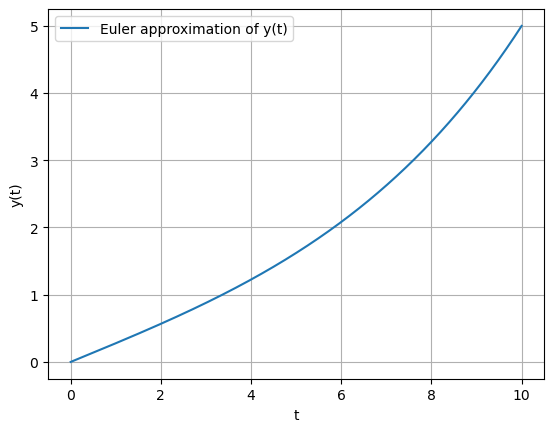

I( 10 )= 4.9950810288564655


In [96]:
import numpy as np
import matplotlib.pyplot as plt


def euler_method_2nd_order(f, t_span, y0, y1, h):
    """Approximate y for y'' = f(t, y, y') using Euler's method.

    Convert the second-order ODE to the first-order system
        y' = z
        z' = f(t, y, z)

    Args:
        f: Acceleration function, f(t, y, z).
        t_span: Tuple (t0, tf) for the time interval.
        y0: Initial value y(t0).
        y1: Initial derivative y'(t0).
        h: Step size.

    Returns:
        Arrays t and y containing the time points and approximation of y(t).
    """
    t0, tf = t_span
    t = np.arange(t0, tf + h, h)
    n = len(t)
    y = np.zeros(n)
    z = np.zeros(n)
    y[0] = y0
    z[0] = y1

    for i in range(n - 1):
        y[i + 1] = y[i] + h * z[i]
        z[i + 1] = z[i] + h * f(t[i], y[i], z[i])

    return t, y, z


p=0.2
G =5
T=10



# Example: solve y'' = -y with y(0) = 0 and y'(0) = 1, from t=0 to t=5.
def f(t, y, z):
    return (p**2)*y


t_span = (0, T)
y0 = 0
y1 = 0.276
h = 0.01

t, y, z = euler_method_2nd_order(f, t_span, y0, y1, h)

plt.plot(t, y, linestyle='-', label="Euler approximation of y(t)")
plt.xlabel('t')
plt.ylabel('y(t)')
plt.grid(True)
plt.legend()
plt.show()

print('I(',T,')=',y[-1])

In [37]:
for i in range(0,T+1):
    I = y[int(i/h)]
    print('I(',i,')=',I)

I( 0 )= 0.0
I( 1 )= 0.277788495525803
I( 2 )= 0.5666123145648129
I( 3 )= 0.8780562592300132
I( 4 )= 1.2246081436735703
I( 5 )= 1.6201595133982511
I( 6 )= 2.080562489817039
I( 7 )= 2.624265061311005
I( 8 )= 3.273050280817867
I( 9 )= 4.052908989108635
I( 10 )= 4.9950810288564655


In [108]:
t_span = (0,10)
h = 0.01


def get_initial_der(F,G=5, tol=0.001, Niter=1000, y1=0, y2=1):

    # y1 = 0
    t, y, z = euler_method_2nd_order(F, t_span, 0, y1, h)
    G1 = y[-1]
    
    # y2 = 1
    t, y, z = euler_method_2nd_order(F, t_span, 0, y2, h)
    G2 = y[-1]
    

    bool=1
    iter=0

    while bool:
        ynew = (y1+y2)/2
        t, y, z = euler_method_2nd_order(F, t_span, 0, ynew, h)
        Gnew = y[-1]

        if ((G1-G)*(Gnew-G) < 0):
            y2 = ynew
            G2 = Gnew
        else:
            y1 = ynew
            G1 = Gnew

        if (np.abs(G-Gnew) < tol) :
            bool=0
            # print('Success')
        else:
            iter += 1
            bool = (Niter > iter)

    print('Iterations: ',iter)
    print("y'(0)=", ynew)
    print('y(10)=',Gnew)
    return ynew, Gnew


# def Riemann_Sum(F, y1):
    
#     # y1 = get_initial_der(F)
#     t, y, z = euler_method_2nd_order(F, t_span, 0, y1, h)

#     n = len(t)
#     S = 0

#     for i in range(n):
#         S += h*(z[i]+p*y[i])**2

#     return S


def Riemann_Sum(f, t):
    
    n = len(t)
    
    S = 0

    for i in range(n):
        S += h*f[i]

    return S


#### Correct Answer

Iterations:  17
y'(0)= 276.2718200683594
y(10)= 5000.000460982274


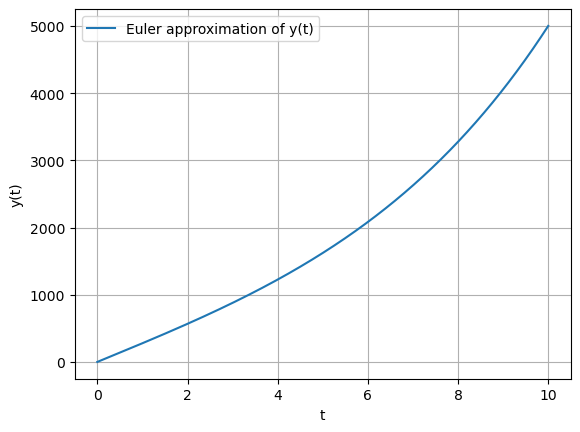


Optimal production cost = 10217143.605141655

Number of broken glasses = 3815.2139687774898
Total number of glasses produced = 8815.21396877749
glasses broken / glasses produced = 0.43279879334642973


In [112]:
# Define the ODE y'' = F(t,y,y') for t in [0,10]
# where z = y'

G = 5000

def F(t, y, z):
    return (p**2)*y


# Find the initial derivative y'(0)=z(0) that yields y(10)=5

y1, G1 = get_initial_der(F, G,Niter = 100, y2=1000)

# Use a Riemann sum to calculate the integral for the Optimal production cost

#   obtain the optimal inventory
t, y, z = euler_method_2nd_order(F, t_span, 0, y1, h)

# Plot the graph of their solution

plt.plot(t, y, linestyle='-', label="Euler approximation of y(t)")
plt.xlabel('t')
plt.ylabel('y(t)')
plt.grid(True)
plt.legend()
plt.show()

#   define the function to integrate
f = (z + p*y)**2

#   calculate the Riemann sum
RS = Riemann_Sum(f, t)

print('\nOptimal production cost =',RS)


# Use a Riemann sum to calculate the number of broken glasses

RS = Riemann_Sum(p*y, t)

print('\nNumber of broken glasses =',RS)

print('Total number of glasses produced =', G+RS)
print('glasses broken / glasses produced =', RS/(G+RS))





#### Check Student Answer

Inputs:
* Value for $h$ - resolution of solution
* Student's function $F(t,y,z)$
* Student's value for $G$ (either 5 or 5000)

Outputs:
* Student's value for $I'(0)$ _(and number of iterations needed to find it - if 100, then code aborted before finding the correct value)_
* Graph of $I(t)$
* Optimal production cost
* Number of broken glasses

Iterations:  21
y'(0)= 275.775671005249
y(10)= 4999.999351521228


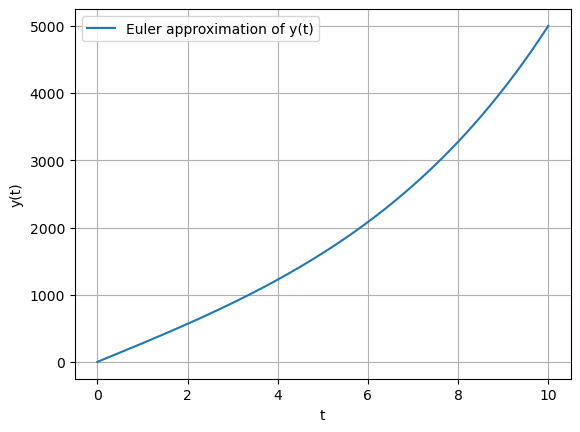


Optimal production cost = 10189627.01672691

Number of broken glasses = 3808.6945656689795


In [117]:
# Define the ODE y'' = F(t,y,y') for t in [0,10]
# where z = y'

G = 5000
h=0.01

def F(t, y, z):
    return (p**2)*y


# Find the initial derivative y'(0)=z(0) that yields y(10)=5

y1, G1 = get_initial_der(F, G, Niter = 100, y2=1000)

# Use a Riemann sum to calculate the integral for the Optimal production cost

#   obtain the optimal inventory
t, y, z = euler_method_2nd_order(F, t_span, 0, y1, h)

# Plot the graph of their solution

plt.plot(t, y, linestyle='-', label="Euler approximation of y(t)")
plt.xlabel('t')
plt.ylabel('y(t)')
plt.grid(True)
plt.legend()
plt.show()

#   define the function to integrate
f = (z + p*y)**2

#   calculate the Riemann sum
RS = Riemann_Sum(f, t)

print('\nOptimal production cost =',RS)


# Use a Riemann sum to calculate the number of broken glasses

RS = Riemann_Sum(p*y, t)

print('\nNumber of broken glasses =',RS)

# print('Total number of glasses produced =', G+RS)
# print('glasses broken / glasses produced =', RS/(G+RS))



